<h1 align="center" style="color:blue">Discovering Topics in Online Discussions</h1>
<h2 align="center" style="color:blue">Classification and Clustering</h2>
<h3 align="center" style="color:red">DTAN-520: Text Mining</h3>
<h3 align="center" style="color:red">Indiana Wesleyan University</h3>
<h4 align="center">Fall 2026 | Two-Day In-Person Residency</h4>
<h5 align="right">Instructor: Dr. Eskinder Belete<br>Date: November 2026</h5>

#### Student lab notebook | Six teams of five | Upload the provided group CSV

**Research question**: How can we organize discussions while respecting context and privacy?

**Your mission**: Run the prepared cells, interpret evidence, discuss tradeoffs, and present your findings. No coding from scratch is required.

**Data**: `Group3_Online_Discussions_20Newsgroups.csv` - [Original source](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset) - Core methods: Term Frequency-Inverse Document Frequency (TF-IDF), supervised classification, K-means clustering.

## Table of Contents

1. [Introduction - Mission and dataset](#introduction--mission-and-dataset)
2. [Key Terms and Concepts](#key-terms-and-concepts)
3. [Activity 1 - Explore and Understand the Text](#activity-1--explore-and-understand-the-text)
4. [Activity 2 - Apply and Evaluate Machine Learning](#activity-2--apply-and-evaluate-machine-learning)
5. [Activity 3 - Business Decisions and Responsible AI](#activity-3--business-decisions-and-responsible-ai)
6. [Final Submission Checklist](#final-submission-checklist)
7. [Source and reproducibility notes](#source-and-reproducibility-notes)

8. [References - APA 7th Edition](#references--apa-7th-edition)
9. [License and Copyright](#license-and-copyright)

<a id="introduction--mission-and-dataset"></a>
## Introduction - Mission and dataset

**Problem**: How can we organize discussions while respecting context and privacy?

**Dataset**: selected discussion communities. The instructor-provided CSV has `text`, `label`, and `label_name` columns.

**Learning goals**: (1) explain TF-IDF terms; (2) evaluate classification using precision, recall, and macro F1; (3) interpret K-means themes; (4) recommend a responsible organizational action.

**Before running**: Put `Group3_Online_Discussions_20Newsgroups.csv` beside this notebook. In Colab, the first cell will offer an upload if the file is not present. Run cells top to bottom. The notebook uses a fixed random seed for reproducibility.

<a id="key-terms-and-concepts"></a>
## Key Terms and Concepts

*Use this quick reference while you interpret your outputs.*

| Term | Concise definition |
|---|---|
| Text preprocessing | Preparing text for analysis, such as standardizing whitespace. |
| Class / label | A known category assigned to a text record. |
| Class imbalance | Some labels have substantially more examples than others. |
| Term Frequency-Inverse Document Frequency (TF-IDF) | A numerical representation that gives weight to terms that help distinguish documents. |
| Training/test split | Separating examples used to fit a model from examples used to evaluate it. |
| Data leakage | Allowing information from evaluation data to influence model training. |
| Classification | Predicting a predefined label for a new text. |
| Accuracy | Fraction of all test predictions that are correct. |
| Precision | Among texts predicted as a class, the fraction actually belonging to that class. |
| Recall | Among texts actually in a class, the fraction correctly identified. |
| F1-score | Harmonic mean of precision and recall. |
| Support | Number of actual test examples in a class. |
| Macro average / macro F1 | Unweighted mean of class-level scores; each class counts equally. |
| Weighted average | Mean of class-level scores weighted by each class's support. |
| Confusion matrix | Table of actual versus predicted labels showing correct and incorrect predictions. |
| False positive / false negative | A mistaken positive prediction / a missed actual positive, for a chosen class. |
| K-means clustering | Grouping texts by similarity without using their known labels. |
| Cluster centroid | The center of a cluster in its numerical feature space. |
| Two-dimensional (2D) projection | A simplified view of high-dimensional text data; plotted distances may be distorted. |
| Adjusted Rand Index (ARI) | Measure of agreement between discovered clusters and known labels, adjusted for chance; low ARI does not make clustering automatically useless. |

**Remember**: Classification predicts known labels; clustering explores possible groupings. Neither automatically establishes causality, fairness, or business readiness.

**Research foundations**: TF-IDF weighting is grounded in Salton and Buckley (1988); automated text classification in Sebastiani (2002); and the software implementation in Pedregosa et al. (2011).

<a id="activity-1--explore-and-understand-the-text"></a>
<div style="background:#e8f7f5;padding:13px;border-left:7px solid #137c83;border-radius:8px;color:#174c51"><h2 style="margin:0">ACTIVITY 1 - Explore and Understand the Text</h2><p style="margin:5px 0">Preview to clean to visualize to interpret</p></div>

1.1 Load and preview. Run the next cell. If prompted, upload your team's CSV.

In [1]:
from pathlib import Path
import re, html, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, adjusted_rand_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline

SEED = 520
FILE = r"C:\Users\Daily\OneDrive\Documents\New folder\DTAN-520 Text Mining\Residency\Datasets\Residency Datasets and Projects\DTAN520_Student_Datasets\Group3_Online_Discussions_20Newsgroups.csv"
path = Path(FILE)
if not path.exists():
    try:
        from google.colab import files
        print(f"Upload {FILE} to continue.")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place {FILE} in the notebook's working folder.")
assert Path(FILE).exists(), f"Missing {FILE}"
df = pd.read_csv(FILE)
assert {'text', 'label', 'label_name'}.issubset(df.columns)
df = df[['text', 'label', 'label_name']].dropna().copy()
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'].ne('')].drop_duplicates('text').reset_index(drop=True)
print(f"Group 3: {len(df):,} documents | {df.label_name.nunique()} classes")
display(df[['text', 'label_name']].head(4))

Group 3: 3,000 documents | 4 classes


,text,label_name
0,jayson stark (i trhink that's him) fits perfec...,rec.sport.baseball
1,:>re: majority of users not readding from flop...,comp.graphics
2,I want All-Star Tickets does anyone know how I...,rec.sport.baseball
3,Greeting I am starting work on a project where...,sci.med


<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - Dataset preview</div>

- What the output shows: Each row is one text record; `label_name` identifies its known category.
- What to examine: Confirm the sample texts fit the business problem and note the number of records.
- What to explain: Describe one example and why it matters; the classroom sample may not represent the entire original dataset.

1.2 Prepare and inspect the text. Light normalization removes URLs and extra spaces while preserving most word meaning. Inspect the chart and example texts before modeling.

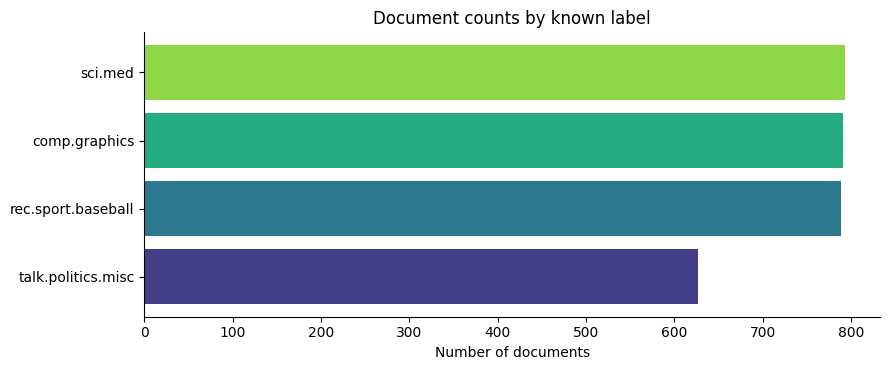

Median document length: 83 words


In [2]:
def clean_text(s):
    s = html.unescape(str(s))
    s = re.sub(r'https?://\S+|www\.\S+', ' URL ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

df['clean_text'] = df['text'].map(clean_text)
df['words'] = df['clean_text'].str.split().str.len()
counts = df['label_name'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(counts.index, counts.values, color=plt.cm.viridis(np.linspace(.18,.83,len(counts))))
ax.set(title='Document counts by known label', xlabel='Number of documents')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()
print('Median document length:', int(df.words.median()), 'words')

<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - Class distribution and text length</div>

- What the charts show: The number of texts per label and the typical document length.
- What to examine: Identify the largest and smallest classes; consider whether imbalance could mask errors.
- What to explain: State one implication for model evaluation and one question about data representativeness.

1.3 TF-IDF: what words distinguish the texts? This is an *exploratory* fit on the full dataset; classification below uses a separate training-only fit to avoid test leakage.

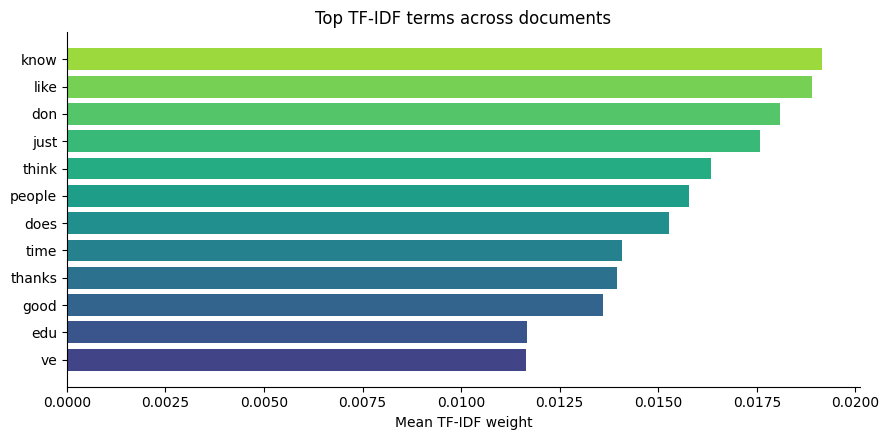

In [3]:
explore_tfidf = TfidfVectorizer(stop_words='english', min_df=2, max_df=.95,
                                  max_features=3500, ngram_range=(1,2), sublinear_tf=True)
X_all = explore_tfidf.fit_transform(df['clean_text'])
terms = np.array(explore_tfidf.get_feature_names_out())
scores = np.asarray(X_all.mean(axis=0)).ravel()
top = np.argsort(scores)[-12:]
fig, ax = plt.subplots(figsize=(9,4.5))
ax.barh(terms[top], scores[top], color=plt.cm.viridis(np.linspace(.2,.85,len(top))))
ax.set(title='Top TF-IDF terms across documents', xlabel='Mean TF-IDF weight')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - TF-IDF terms</div>

- What the chart shows: Terms with high average Term Frequency-Inverse Document Frequency (TF-IDF) weights, not raw word counts.
- What to examine: Choose two terms that relate to the business problem and one that may be generic or misleading.
- What to explain: Connect the terms to example texts without treating term weights as proof of causation.

<div style="background:#e9f8f5;padding:14px;border-left:6px solid #137c83;border-radius:8px">FORMAL GROUP PRESENTATION 1 - ACTIVITY 1 - 5-7 MINUTES</div>

Present professionally using slides or clearly organized notebook visuals.

Deliverables:
- Introduce the business question, dataset, and labels.
- Display and explain the class-distribution chart and TF-IDF term chart.
- Present three evidence-based observations and one question to investigate.
- Explain the relevance of the observed patterns to the organization.

Discussion questions:
- Which discussion categories overlap, and what could make a cluster misleading?
- How might class imbalance or sample selection influence your findings?

Participation and evidence:
- All five group members must speak and explain their own contribution.
- Use labeled charts, actual findings, and concise conclusions. Do not simply read slides.
- Divide speaking time fairly and be prepared for instructor questions.

<a id="activity-2--apply-and-evaluate-machine-learning"></a>
<div style="background:#f2ecfa;padding:13px;border-left:7px solid #6d4ca2;border-radius:8px;color:#45335f"><h2 style="margin:0">ACTIVITY 2 - Apply and Evaluate Machine Learning</h2><p style="margin:5px 0">Classify to evaluate to cluster to explain</p></div>

2.1 Classification. The model learns only from training texts. We evaluate on a held-out 20% test set, using macro F1 so smaller classes matter.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label_name'], test_size=.20, stratify=df['label_name'],
    random_state=SEED)
classifier = make_pipeline(
    TfidfVectorizer(stop_words='english', min_df=2, max_df=.95,
                    max_features=5000, ngram_range=(1,2), sublinear_tf=True),
    LogisticRegression(max_iter=1200, class_weight='balanced', random_state=SEED))
classifier.fit(X_train, y_train)
pred = classifier.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, pred):.3f} | Macro F1: {f1_score(y_test, pred, average="macro"):.3f}')
print(classification_report(y_test, pred, zero_division=0))

Accuracy: 0.908 | Macro F1: 0.907
                    precision    recall  f1-score   support

     comp.graphics       0.91      0.95      0.93       158
rec.sport.baseball       0.94      0.88      0.91       158
           sci.med       0.93      0.89      0.91       159
talk.politics.misc       0.84      0.92      0.88       125

          accuracy                           0.91       600
         macro avg       0.91      0.91      0.91       600
      weighted avg       0.91      0.91      0.91       600



<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - Classification report</div>

- What the report shows: Precision is the share of predictions for a class that are correct; recall is the share of actual class examples found.
- How to read it: F1-score balances precision and recall; support is the number of actual test examples for a class.
- What to compare: Identify the lowest class F1-score and explain why macro F1 treats all classes equally while weighted F1 reflects class sizes.
- What to explain: A high overall accuracy can hide weak results for smaller classes. Which discussion categories overlap, and what could make a cluster misleading?

2.2 Model errors. A confusion matrix shows which labels the classifier mixes up. Examine real errors rather than relying on accuracy alone.

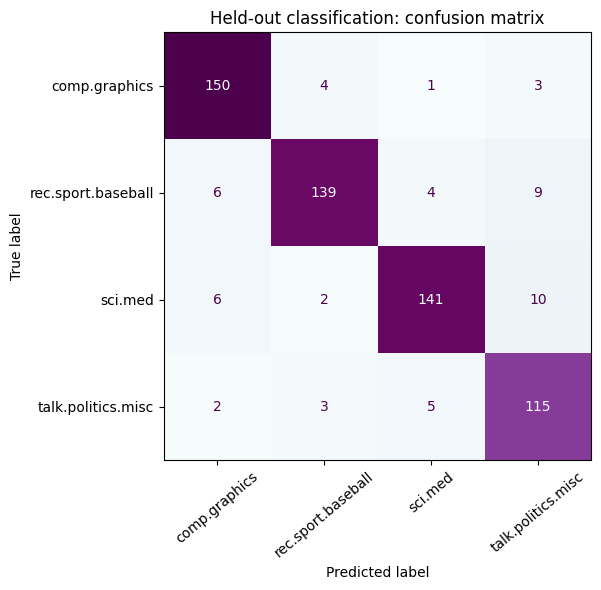

Misclassified test documents: 55


,text,actual,predicted
15,What's with John Franco? The Mets are hardly u...,rec.sport.baseball,comp.graphics
23,GT> From: gary@concave.cs.wits.ac.za (Gary Tay...,sci.med,comp.graphics
29,"That study which was in the NEJM, I think, not...",talk.politics.misc,sci.med
41,"Actually, I was simply relaying the reasoning ...",rec.sport.baseball,talk.politics.misc
42,"I agree, although I would have no idea how to ...",rec.sport.baseball,talk.politics.misc


In [5]:
fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='BuPu',
                                        xticks_rotation=40, colorbar=False)
ax.set_title('Held-out classification: confusion matrix')
plt.tight_layout(); plt.show()
errors = pd.DataFrame({'text':X_test.to_numpy(), 'actual':y_test.to_numpy(), 'predicted':pred})
errors = errors[errors.actual != errors.predicted]
print('Misclassified test documents:',len(errors))
display(errors.head(5))

<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - Confusion matrix and errors</div>

- What the chart shows: Rows represent actual classes; columns represent predicted classes; diagonal cells are correct predictions.
- What to examine: Find one important off-diagonal error and read the corresponding misclassified text.
- What to explain: Describe a plausible source of confusion and the business cost of this error. Which discussion categories overlap, and what could make a cluster misleading?

2.3 K-means clustering. Clusters are discovered without looking at the known labels. We start with 4 clusters for comparison, but cluster numbers do not have to correspond to class names. Inspect top words and example texts.

In [6]:
N_CLUSTERS = 4
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10)
df['cluster'] = kmeans.fit_predict(X_all)
cluster_terms = []
for c in range(N_CLUSTERS):
    top_words = terms[np.argsort(kmeans.cluster_centers_[c])[-7:][::-1]]
    cluster_terms.append(', '.join(top_words))
summary = pd.DataFrame({'cluster':range(N_CLUSTERS),
                        'documents':df.cluster.value_counts().reindex(range(N_CLUSTERS),fill_value=0).values,
                        'top_terms':cluster_terms})
display(summary)
print('Adjusted Rand Index vs known labels:', round(adjusted_rand_score(df.label_name, df.cluster),3))
print('Note: low label agreement does not automatically mean clusters are unhelpful.')

,cluster,documents,top_terms
0,0,66,"intellect geb, surrender soon, cadre dsl, dsl,..."
1,1,551,"game, year, games, team, baseball, hit, think"
2,2,1707,"people, just, don, think, like, know, time"
3,3,676,"thanks, graphics, file, know, files, image, mail"


Adjusted Rand Index vs known labels: 0.311
Note: low label agreement does not automatically mean clusters are unhelpful.


<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - K-means cluster summary</div>

- What the output shows: K-means groups texts without using the known labels; cluster numbers are identifiers, not class names.
- What to examine: Compare cluster sizes, top centroid terms, and representative texts before suggesting a theme.
- What to explain: Adjusted Rand Index (ARI) measures agreement with known labels, but a low score does not automatically invalidate exploratory clustering.

2.4 Visualize and interpret clusters. The scatter plot is a two-dimensional approximation of high-dimensional TF-IDF. Colors indicate discovered clusters, not true labels. Read representative texts before naming a cluster.

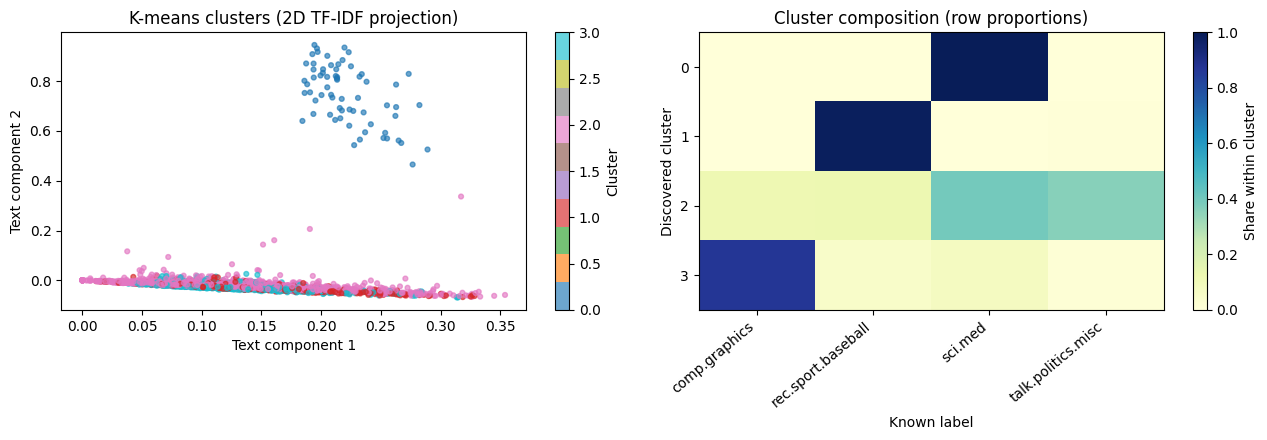


CLUSTER 0: intellect geb, surrender soon, cadre dsl, dsl, edu shameful, geb cadre, cadre
 • Senile keratoses. Have nothing to do with the liver. -- ---------------------------------------------------------------------------- Gordon Banks N3JXP | "Skepticism is the chastity of the intellect, and geb@cadre.dsl.pitt.edu | i
 • So just what was it you wanted to say? -- ---------------------------------------------------------------------------- Gordon Banks N3JXP | "Skepticism is the chastity of the intellect, and geb@cadre.dsl.pitt.edu | it is shameful 

CLUSTER 1: game, year, games, team, baseball, hit, think
 • The problem with your nihilistic approach, Roger, is that it takes all the sense out of the game. By your line of reasoning, if a guy hits into a double play with one out and the bases loaded, there's no point in saying that that 
 • Oh, yeah. Dave Winfield--marginal player. Guy didn't hit a lick, had negligible power, was a crap fielder and had no staying power. Dave Winfield, 

In [7]:
svd = TruncatedSVD(n_components=2, random_state=SEED)
xy = svd.fit_transform(X_all)
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
scatter = axes[0].scatter(xy[:,0],xy[:,1],c=df.cluster, cmap='tab10', s=12,alpha=.65)
axes[0].set(title='K-means clusters (2D TF-IDF projection)',xlabel='Text component 1',ylabel='Text component 2')
fig.colorbar(scatter,ax=axes[0],label='Cluster')
heat = pd.crosstab(df.cluster,df.label_name,normalize='index').reindex(range(N_CLUSTERS)).fillna(0)
image = axes[1].imshow(heat.values,aspect='auto',cmap='YlGnBu',vmin=0,vmax=1)
axes[1].set(xticks=np.arange(len(heat.columns)),xticklabels=heat.columns,
            yticks=np.arange(len(heat.index)),yticklabels=heat.index,
            xlabel='Known label',ylabel='Discovered cluster',title='Cluster composition (row proportions)')
plt.setp(axes[1].get_xticklabels(),rotation=40,ha='right')
fig.colorbar(image,ax=axes[1],label='Share within cluster')
plt.tight_layout();plt.show()
# Closest-to-center examples; these are illustrative, not validation scores.
for c in range(N_CLUSTERS):
    member_ids = np.flatnonzero(df.cluster.to_numpy()==c)
    if len(member_ids)==0: continue
    distances = kmeans.transform(X_all[member_ids])[:,c]
    chosen = member_ids[np.argsort(distances)[:2]]
    print(f'\nCLUSTER {c}: {cluster_terms[c]}')
    for j in chosen: print(' •',df.iloc[j]['clean_text'][:230])

<div style="background:#f5f8fc;padding:11px 14px;border-left:5px solid #377ba8;border-radius:8px">How to interpret - Cluster visualization</div>

- What the charts show: Colors indicate discovered clusters in a two-dimensional (2D) approximation of TF-IDF space; the composition chart compares clusters with known labels.
- What to examine: Identify one apparent pattern and confirm it using top terms and representative texts.
- What to explain: Projection can distort distances; cluster membership does not prove that texts share a single meaning.

<div style="background:#f3edfb;padding:14px;border-left:6px solid #6d4ca2;border-radius:8px">FORMAL GROUP PRESENTATION 2 - ACTIVITY 2 - 5-7 MINUTES</div>

Present professionally using slides or clearly organized notebook visuals.

Deliverables:
- Present the classification report, confusion matrix, K-means summary, and cluster visualization.
- Report macro F1 and compare at least two classes using precision, recall, F1-score, and support.
- Explain one consequential classification error using a real example.
- Propose one cluster theme supported by top terms and text examples; explain one limitation.

Discussion questions:
- Which discussion categories overlap, and what could make a cluster misleading?
- Why might K-means clusters differ from the predefined class labels?

Participation and evidence:
- All five group members must speak and explain their own contribution.
- Use labeled charts, actual findings, and concise conclusions. Do not simply read slides.
- Divide speaking time fairly and be prepared for instructor questions.

<a id="activity-3--business-decisions-and-responsible-ai"></a>
<div style="background:#fff4e5;padding:13px;border-left:7px solid #c28122;border-radius:8px;color:#6d491a"><h2 style="margin:0">ACTIVITY 3 - Business Decisions and Responsible AI</h2><p style="margin:5px 0">Recommend to weigh costs to protect people to present</p></div>

3.1 Make a recommendation. Return to the decision challenge: How can we organize discussions while respecting context and privacy? Use two specific pieces of evidence from Activities 1-2.

3.2 Evaluate tradeoffs. Discuss the cost of wrong predictions, human review, maintenance, and data quality. Ethical risk: Discussion text may include sensitive claims and legacy cultural context.

3.3 Responsible AI checklist. Address privacy, fairness, transparency, security, consent, and human oversight. What should *not* be automated? Who is accountable when the system is wrong?

<div style="background:#fff1dc;padding:14px;border-left:6px solid #c28122;border-radius:8px">FORMAL GROUP PRESENTATION 3 - ACTIVITY 3 - 8 MINUTES (6 PRESENTATION + 2 Q&A)</div>

Present professionally using slides or clearly organized notebook visuals.

Deliverables:
- State one actionable business recommendation supported by at least two findings from Activities 1 and 2.
- Show at least one chart, one meaningful classification error, and one evidence-supported cluster insight.
- Discuss expected value, the cost of mistakes, and limits of the classroom sample.
- Address privacy, fairness, transparency, consent, security, and human oversight.
- Propose one practical safeguard or next step and distinguish evidence from assumptions.

Discussion questions:
- How could moderation or search recommendations be affected by misclassification?
- What additional testing or human review is needed before deployment?

Participation and evidence:
- All five group members must speak and explain their own contribution.
- Use labeled charts, actual findings, and concise conclusions. Do not simply read slides.
- Divide speaking time fairly and be prepared for instructor questions.

<a id="final-submission-checklist"></a>
## Final Submission Checklist

- [ ] Complete Activities 1, 2, and 3, including the charts and model outputs.
- [ ] Explain the class distribution, TF-IDF terms, classification metrics, confusion matrix, and clusters.
- [ ] Present evidence-based findings and a defensible business recommendation.
- [ ] Address responsible Artificial Intelligence (AI), including human oversight and relevant risks.
- [ ] Ensure all five members contribute to each formal group presentation.
- [ ] Save the completed notebook and presentation slides or selected visuals.


<a id="source-and-reproducibility-notes"></a>
## Source and reproducibility notes

- Original dataset: [https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset). The instructor supplied a cleaned, possibly sampled classroom CSV; it may not match the source's full size or label selection.
- Reproducibility: seed `520`; stratified 80/20 holdout; TF-IDF fitted on training text for supervised classification; clustering fitted separately to all text without using labels.
- Interpretation: The displayed test results come from a single split, not deployment validation. Two-dimensional cluster plots distort distances; inspect actual text. No model proves causality or fairness.
- Sharing: Review original-source licensing and potential personal information before uploading classroom data to public GitHub.

<a id="references--apa-7th-edition"></a>
## References - APA 7th Edition

<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. In <em>Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability</em> (Vol. 1, pp. 281-297). University of California Press. https://projecteuclid.org/euclid.bsmsp/1200512992</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">National Institute of Standards and Technology. (2023). <em>Artificial intelligence risk management framework (AI RMF 1.0)</em> (NIST AI 100-1). https://doi.org/10.6028/NIST.AI.100-1</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., &amp; Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. <em>Journal of Machine Learning Research, 12</em>, 2825-2830. https://jmlr.org/papers/v12/pedregosa11a.html</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">Salton, G., &amp; Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. <em>Information Processing &amp; Management, 24</em>(5), 513-523. https://doi.org/10.1016/0306-4573(88)90021-0</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">Scikit-learn developers. (n.d.). <em>The 20 newsgroups text dataset</em> [Data set documentation]. https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">Sebastiani, F. (2002). Machine learning in automated text categorization. <em>ACM Computing Surveys, 34</em>(1), 1-47. https://doi.org/10.1145/505282.505283</p>
<p style="margin:0 0 12px 0;padding-left:28px;text-indent:-28px;line-height:1.65">Sokolova, M., &amp; Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. <em>Information Processing &amp; Management, 45</em>(4), 427-437. https://doi.org/10.1016/j.ipm.2009.03.002</p>

**Dataset provenance:** The classroom CSV is an instructor-prepared, cleaned and/or sampled version of the source dataset. Cite the original dataset in written work. External datasets and software retain their own licenses and attribution requirements.

<a id="license-and-copyright"></a>
## License and Copyright

**Author:** Dr. Eskinder Belete  
**Copyright:** © 2026 Dr. Eskinder Belete  
**Institution:** Indiana Wesleyan University  
**Educational resource:** DTAN-520: Text Mining, Fall 2026  
**License:** MIT License

This companion notebook is intended for educational use and is distributed under the MIT License. The full license text is available at https://opensource.org/licenses/MIT. External libraries, source publications, and datasets remain subject to their respective terms and attribution requirements.